# Programming Sheet 6: Regression

We predict a real number from an input: with ridge regression, with kernel ridge regression and with a Gaussian process, on the cars of the lecture. Each model builds on the one before.

**Quiz.** Each exercise asks for one function, with the same name and arguments as in the ISIS quiz for this sheet, which also contains a few short multiple-choice questions. The quiz checks your functions on several inputs and explains with figures what they compute. This week the quiz counts all 100 points of week 6.

In [1]:
import numpy as np
import matplotlib
%matplotlib inline
from matplotlib import pyplot as plt
import utils

## Data: The Cars of the Lecture

The Auto MPG data: the horsepower and the fuel efficiency in miles per gallon (mpg) of 392 cars built between 1970 and 1982. As in the lecture, 20 cars are the training data (black) and the other 372 the test data (gray).

All models work with rescaled data. The input is $x = (\text{horsepower} - 138) / 92$, which lies between $-1$ and $1$. The targets $y$ are standardized with the mean and the standard deviation of the training targets: they have mean zero, so the models need no bias. Errors are given in the original unit: `rmse` is the root of the mean squared error in mpg. As in the previous sheets, the data points are the rows of an array: `X_train` has shape (20, 1).

training targets: mean 22.0 mpg, standard deviation 7.7 mpg


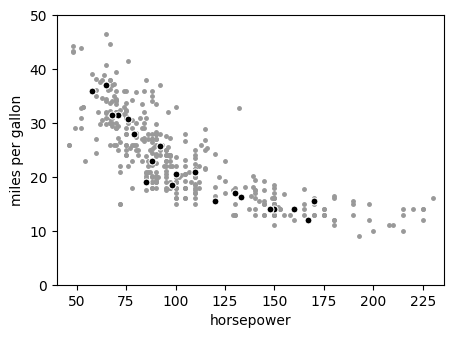

In [2]:
hp_train, mpg_train, hp_test, mpg_test = utils.cars()
mpg_mean, mpg_std = mpg_train.mean(), mpg_train.std()

def scale(hp):
    # horsepower -> input x, an array of shape (N, 1)
    return ((hp - 138) / 92)[:, None]

def to_mpg(y):
    # standardized target -> miles per gallon
    return y * mpg_std + mpg_mean

def rmse(f, y):
    # error in mpg of the predictions f for the standardized targets y
    return np.sqrt(np.mean((f - y) ** 2)) * mpg_std

X_train, X_test = scale(hp_train), scale(hp_test)
X_grid = scale(utils.HP_GRID)
y_train = (mpg_train - mpg_mean) / mpg_std
y_test = (mpg_test - mpg_mean) / mpg_std
print(f'training targets: mean {mpg_mean:.1f} mpg, '
      f'standard deviation {mpg_std:.1f} mpg')

fig, ax = plt.subplots(figsize=(5, 3.5))
utils.plot_cars(ax, hp_train, mpg_train, hp_test, mpg_test)
plt.show()

## Exercise 1: Ridge Regression

For centered inputs and targets, the linear model $f(\boldsymbol{x}) = \boldsymbol{w}^\top \boldsymbol{x}$ needs no bias. Ridge regression minimizes the square error plus a penalty on the weights,

$$
\sum_{i=1}^N \big(\boldsymbol{w}^\top \boldsymbol{x}_i - y_i\big)^2 + \lambda \|\boldsymbol{w}\|^2 ,
$$

and the lecture derived the solution $\boldsymbol{w} = (XX^\top + \lambda I)^{-1} X \boldsymbol{y}$ for a matrix $X$ with the data points as *columns*. In code, the data points are the *rows* of `X`, an array of shape (N, d): the $d \times d$ matrix $XX^\top$ of the lecture is `X.T @ X` there, and $X\boldsymbol{y}$ is `X.T @ y`.

* **Implement `ridge(X, y, lam)`**, which returns the weights `w`, an array of shape (d,). Solve the linear system with `np.linalg.solve` rather than computing an inverse.

In [3]:
def ridge(X, y, lam):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    w = solutions.ridge(X, y, lam)
    ## -------------------------------

    return w

A line is too stiff for the cars. As in the lecture, we make the model flexible with the powers $x, x^2, \dots, x^{19}$ of the input as features (`utils.polynomial_features`), centered with their means over the training cars: 19 weights for 20 cars.

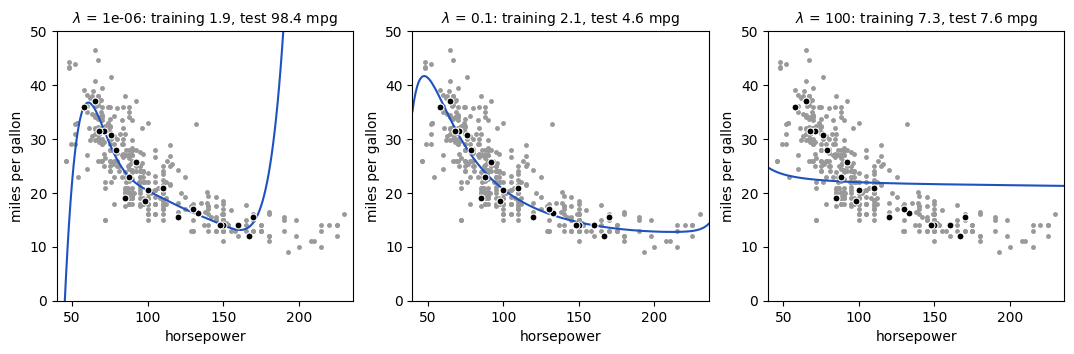

In [4]:
p = 19
F_mean = utils.polynomial_features(X_train[:, 0], p).mean(axis=0)

def features(X):
    # the centered powers of the input, an array of shape (N, p)
    return utils.polynomial_features(X[:, 0], p) - F_mean

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, lam in zip(axes, [1e-6, 0.1, 100]):
    w = ridge(features(X_train), y_train, lam)
    e_train = rmse(features(X_train) @ w, y_train)
    e_test = rmse(features(X_test) @ w, y_test)
    ax.plot(utils.HP_GRID, to_mpg(features(X_grid) @ w),
            color=utils.FIT)
    title = (f'$\\lambda$ = {lam:g}: training {e_train:.1f}, '
             f'test {e_test:.1f} mpg')
    utils.plot_cars(ax, hp_train, mpg_train, hp_test, mpg_test, title)
plt.show()

With almost no regularization, the curve follows the training cars and leaves the plot between them and beyond them. With a very large $\lambda$ the weights vanish, and the prediction is the mean of the training targets. In between, the model predicts the test cars better than both. The errors over the whole range of $\lambda$:

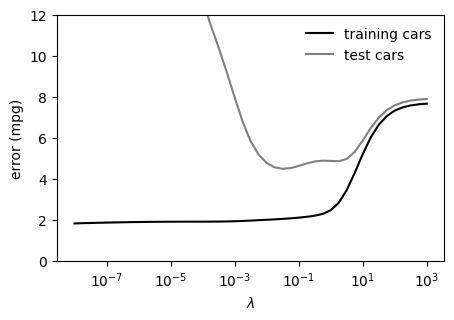

smallest test error 4.50 mpg at lambda = 0.032


In [5]:
lams = 10.0 ** np.arange(-8, 3.01, 0.25)
errors = []
for lam in lams:
    w = ridge(features(X_train), y_train, lam)
    errors.append((rmse(features(X_train) @ w, y_train),
                   rmse(features(X_test) @ w, y_test)))
errors = np.array(errors)

plt.figure(figsize=(5, 3.2))
plt.semilogx(lams, errors[:, 0], color='k', label='training cars')
plt.semilogx(lams, errors[:, 1], color='0.5', label='test cars')
plt.ylim(0, 12)
plt.xlabel('$\\lambda$'); plt.ylabel('error (mpg)')
plt.legend(frameon=False)
plt.show()
print(f'smallest test error {errors[:, 1].min():.2f} mpg '
      f'at lambda = {lams[errors[:, 1].argmin()]:.2g}')

**Question.** The training error is smallest for the smallest $\lambda$, whatever the data. Why? And what follows for the choice of $\lambda$? (One of the multiple-choice questions of the quiz asks about this.)

## Exercise 2: Kernel Ridge Regression

With a feature map $\phi$ and the kernel $k(\boldsymbol{x}, \boldsymbol{x}') = \phi(\boldsymbol{x})^\top \phi(\boldsymbol{x}')$, the prediction of ridge regression in feature space needs the features only through the kernel:

$$
f(\boldsymbol{x}) = k(\boldsymbol{x}, X)\, (K + \lambda I)^{-1} \boldsymbol{y} = \sum_{i=1}^N \alpha_i\, k(\boldsymbol{x}, \boldsymbol{x}_i),
\qquad \boldsymbol{\alpha} = (K + \lambda I)^{-1} \boldsymbol{y},
$$

where $K$ is the $N \times N$ matrix with the entries $K_{ij} = k(\boldsymbol{x}_i, \boldsymbol{x}_j)$ for the training inputs, and $k(\boldsymbol{x}, X) = \big(k(\boldsymbol{x}, \boldsymbol{x}_1), \dots, k(\boldsymbol{x}, \boldsymbol{x}_N)\big)$. We use the Gaussian kernel of width $s$,

$$
k(\boldsymbol{x}, \boldsymbol{x}') = \exp\Big(-\frac{\|\boldsymbol{x} - \boldsymbol{x}'\|^2}{2 s^2}\Big),
$$

which is given in `utils.py`:

```python
def gaussian_kernel(X1, X2, s):
    # kernel matrix of shape (N1, N2) with the entries
    # k(x, x') = exp(-||x - x'||^2 / (2 s^2))
    # for the rows x of X1 (shape (N1, d)) and the rows x' of X2 (shape (N2, d))
    sq = (X1 ** 2).sum(axis=1)[:, None] + (X2 ** 2).sum(axis=1)[None, :] - 2 * X1 @ X2.T
    return numpy.exp(-numpy.maximum(sq, 0) / (2 * s ** 2))
```

In [6]:
from utils import gaussian_kernel

* **Implement `kernel_ridge(X, y, Xs, s, lam)`**, which returns the predictions $f(\boldsymbol{x})$ for the rows $\boldsymbol{x}$ of `Xs` (shape (M, d)), an array of shape (M,). `X` (shape (N, d)) and `y` (shape (N,)) are the training inputs and targets, `s` is the width of the Gaussian kernel and `lam` the regularization parameter $\lambda$.

In [7]:
def kernel_ridge(X, y, Xs, s, lam):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    f = solutions.kernel_ridge(X, y, Xs, s, lam)
    ## -------------------------------

    return f

Three widths of the kernel, given in horsepower (one unit of the input $x$ is 92 hp), with $\lambda = 0.2$:

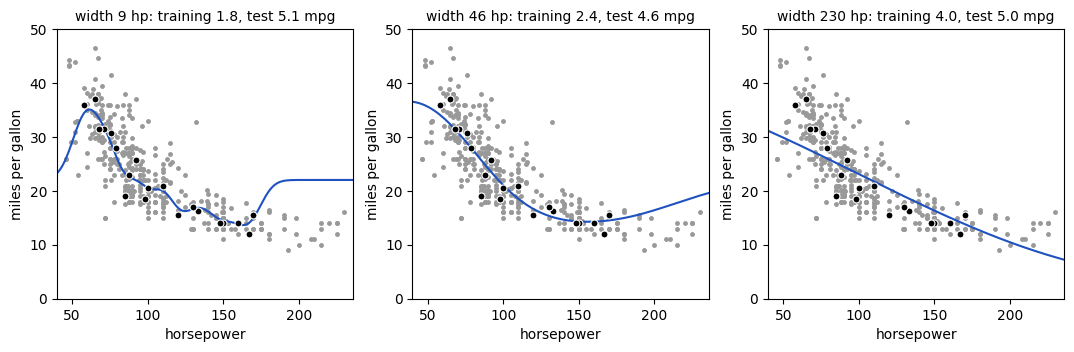

In [8]:
lam = 0.2
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, width_hp in zip(axes, [9, 46, 230]):
    s = width_hp / 92
    f_grid = kernel_ridge(X_train, y_train, X_grid, s, lam)
    e_train = rmse(kernel_ridge(X_train, y_train, X_train, s, lam),
                   y_train)
    e_test = rmse(kernel_ridge(X_train, y_train, X_test, s, lam),
                  y_test)
    ax.plot(utils.HP_GRID, to_mpg(f_grid), color=utils.FIT)
    title = (f'width {width_hp} hp: training {e_train:.1f}, '
             f'test {e_test:.1f} mpg')
    utils.plot_cars(ax, hp_train, mpg_train, hp_test, mpg_test, title)
plt.show()

The width of the kernel sets how flexible the model is: a wide kernel gives a stiff curve, a narrow one a curve that follows the single cars.

**Question.** With the narrow kernel, the curve returns to about 22 mpg between the training cars and to the right of them. Why to this value? (One of the multiple-choice questions of the quiz asks about this.)

## Exercise 3: Gaussian Process

Kernel ridge regression returns one number per input, also at 230 hp, where there are almost no training cars. A Gaussian process gives a distribution. Its prior says that the function values at any inputs are jointly Gaussian with mean zero and the kernel as covariance, $\boldsymbol{f} \sim \mathcal{N}(\boldsymbol{0}, K)$, and the targets are observed with noise, $y_i = f(\boldsymbol{x}_i) + \varepsilon_i$ with $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$. Conditioning on the training targets $\boldsymbol{y}$ gives the distribution of the function values $\boldsymbol{f}_\star$ at new inputs $X_\star$: a Gaussian with

$$
\begin{aligned}
\text{mean} \quad & k(X_\star, X)\, (K + \sigma^2 I)^{-1}\, \boldsymbol{y}\\
\text{covariance} \quad & k(X_\star, X_\star) - k(X_\star, X)\, (K + \sigma^2 I)^{-1}\, k(X, X_\star)
\end{aligned}
$$

where $k(X_\star, X)$ is the kernel matrix between the new inputs and the training inputs.

* **Implement `gp_predict(X, y, Xs, s, sigma)`**, which returns the pair `(mean, cov)` for the function values at the rows of `Xs` (shape (M, d)): the mean, an array of shape (M,), and the covariance, an array of shape (M, M). `X` and `y` are the training inputs and targets, `s` is the width of the Gaussian kernel and `sigma` the standard deviation $\sigma$ of the noise.

In [9]:
def gp_predict(X, y, Xs, s, sigma):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    mean, cov = solutions.gp_predict(X, y, Xs, s, sigma)
    ## -------------------------------

    return mean, cov

The diagonal of the covariance is the variance of each function value. A target is a function value plus noise, $y_\star = f_\star + \varepsilon$, so its variance is larger by $\sigma^2$. The band shows where the Gaussian process expects a car: the mean $\pm$ 2 standard deviations of the target. We condition on the first 2, the first 5 and all 20 training cars, with a kernel of width 46 hp and $\sigma = 0.45$ (3.5 mpg).

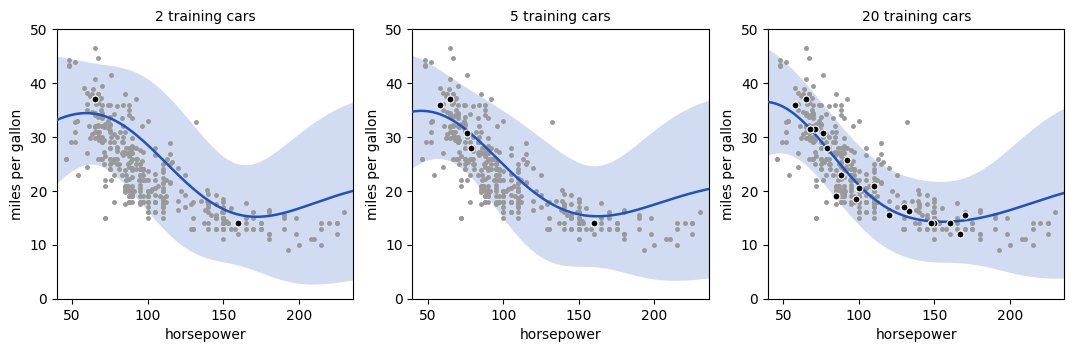

test cars within the band: 91%
largest difference to kernel ridge regression with lambda = sigma^2: 0.0e+00


In [10]:
s, sigma = 0.5, 0.45
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, N in zip(axes, [2, 5, 20]):
    mean, cov = gp_predict(X_train[:N], y_train[:N], X_grid, s, sigma)
    std = np.sqrt(np.diag(cov) + sigma ** 2)
    utils.plot_band(ax, to_mpg(mean), std * mpg_std)
    utils.plot_cars(ax, hp_train[:N], mpg_train[:N], hp_test, mpg_test,
                    title=f'{N} training cars')
plt.show()

mean, cov = gp_predict(X_train, y_train, X_test, s, sigma)
std = np.sqrt(np.diag(cov) + sigma ** 2)
inside = np.mean(np.abs(y_test - mean) <= 2 * std)
print(f'test cars within the band: {inside:.0%}')
f_krr = kernel_ridge(X_train, y_train, X_test, s, sigma ** 2)
print('largest difference to kernel ridge regression with',
      f'lambda = sigma^2: {np.abs(mean - f_krr).max():.1e}')

The mean of the Gaussian process is kernel ridge regression with $\lambda = \sigma^2$: the regularization parameter is a statement about the noise. New is the band, which is narrow where there are training cars and wide where there are none.

**Question.** With all 20 training cars, the band is still about $\pm$ 7 mpg wide where the training cars are dense. Would it shrink to a line with many more training cars? (One of the multiple-choice questions of the quiz asks about this.)

## Exercise 4: Choosing the Kernel Width

The width $s$ of the kernel and the noise $\sigma$ are hyperparameters, like $\lambda$. The training error cannot choose them (Exercise 1). The Gaussian process offers a score that needs the training data only: the probability density that the model assigns to the training targets, the *marginal likelihood*. Under the prior and the noise model, $\boldsymbol{y} \sim \mathcal{N}(\boldsymbol{0}, K + \sigma^2 I)$, so

$$
\log p(\boldsymbol{y} \mid X) = -\frac12\, \boldsymbol{y}^\top (K + \sigma^2 I)^{-1} \boldsymbol{y} - \frac12 \log \det (K + \sigma^2 I) - \frac{N}{2} \log 2\pi .
$$

* **Implement `log_marginal_likelihood(X, y, s, sigma)`**, which returns this number for the training inputs `X` (shape (N, d)) and targets `y` (shape (N,)). For the logarithm of the determinant, use `np.linalg.slogdet(A)[1]`: the determinant itself can be too small to be stored as a number.

In [11]:
def log_marginal_likelihood(X, y, s, sigma):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    value = solutions.log_marginal_likelihood(X, y, s, sigma)
    ## -------------------------------

    return value

We compare three scores for kernel widths between 5 and 400 hp, with $\sigma = 0.45$: the error on the training cars, the log marginal likelihood (divided by the number of training cars), and how well the model predicts the test cars: the mean log density of the test targets, each under its own predictive distribution.

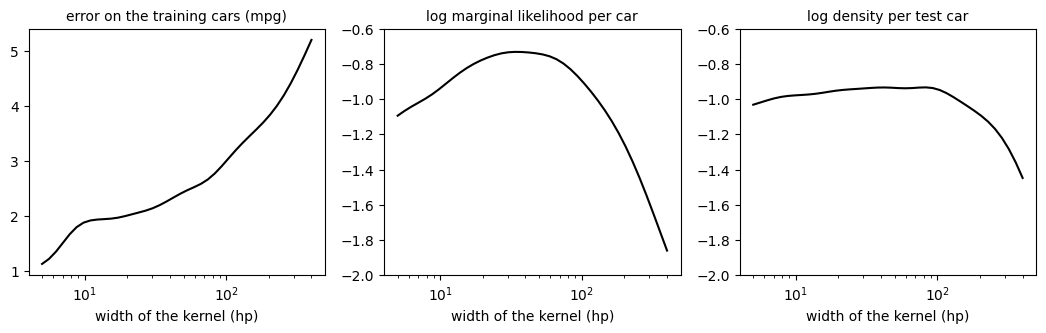

smallest training error:     width 5 hp
largest marginal likelihood: width 34 hp
best on the test cars:       width 83 hp


In [12]:
def log_predictive(X, y, Xs, ys, s, sigma):
    # mean log density of the targets ys at the inputs Xs, each under
    # its own predictive distribution N(mean, variance + sigma^2)
    mean, cov = gp_predict(X, y, Xs, s, sigma)
    var = np.diag(cov) + sigma ** 2
    return np.mean(-0.5 * (ys - mean) ** 2 / var
                   - 0.5 * np.log(2 * np.pi * var))

sigma = 0.45
N = len(X_train)
widths_hp = np.geomspace(5, 400, 40)
train_error, marginal, predictive = [], [], []
for width_hp in widths_hp:
    s = width_hp / 92
    mean, cov = gp_predict(X_train, y_train, X_train, s, sigma)
    train_error.append(rmse(mean, y_train))
    marginal.append(
        log_marginal_likelihood(X_train, y_train, s, sigma) / N)
    predictive.append(
        log_predictive(X_train, y_train, X_test, y_test, s, sigma))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, values, title in zip(axes, [train_error, marginal, predictive],
                             ['error on the training cars (mpg)',
                              'log marginal likelihood per car',
                              'log density per test car']):
    ax.semilogx(widths_hp, values, color='k')
    ax.set_xlabel('width of the kernel (hp)')
    ax.set_title(title, fontsize=10)
axes[1].set_ylim(-2, -0.6); axes[2].set_ylim(-2, -0.6)
plt.show()
for name, best in [('smallest training error', np.argmin(train_error)),
                   ('largest marginal likelihood', np.argmax(marginal)),
                   ('best on the test cars', np.argmax(predictive))]:
    print(f'{name + ":":29s}width {widths_hp[best]:.0f} hp')

The training error prefers the narrowest kernel. The marginal likelihood, computed from the same 20 cars, has its maximum at a medium width, in the range where the model also predicts the test cars best (between about 20 and 100 hp the curve on the right is almost flat).

**Question.** The narrowest kernel fits the training targets best. Why does it not get the largest marginal likelihood? (One of the multiple-choice questions of the quiz asks about this.)

None of the four functions assumes a single input: they work in the same way for inputs with several dimensions, and the quiz tests them there as well.